In [1]:
import numpy as np

In [2]:
omega = np.random.uniform(size=1000)

In [3]:
def height(omega):
    return 1 + 1 / np.exp(omega)

In [4]:
for s in [10, 100, 1000, 10000, 100000, 1000000]:
    print(np.mean(height(np.random.uniform(size=s))))


1.6451171781869345
1.6447477199145093
1.641155678162625
1.6283720546826923
1.6325077127548555
1.6321050245009843


In [5]:
import matplotlib.pyplot as plt

(array([13., 15., 12., 13., 11., 13.,  2.,  4.,  6., 11.]),
 array([1.36796727, 1.43002942, 1.49209156, 1.55415371, 1.61621586,
        1.678278  , 1.74034015, 1.80240229, 1.86446444, 1.92652659,
        1.98858873]),
 <BarContainer object of 10 artists>)

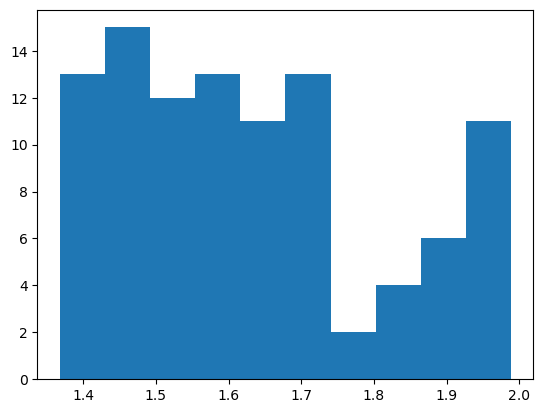

In [6]:
plt.hist(height(np.random.uniform(size=100)))

actual expected value: 1.6666666666666667


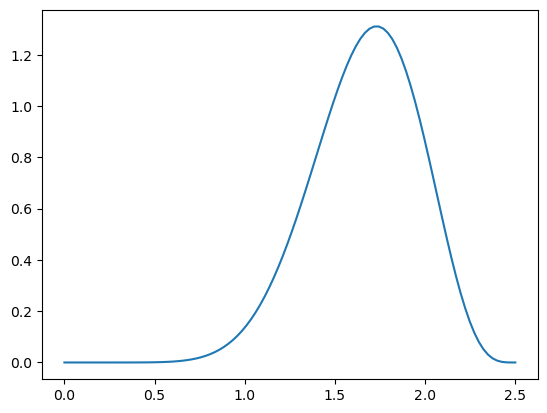

In [12]:
from scipy.stats import beta

# note: we need 
def p_height(h):
    return beta.pdf(h/2.5,10,5)/2.5

X = np.linspace(0,2.5,100)
plt.plot(X,p_height(X))
print ("actual expected value:", 2.5*10/15)

In [15]:
# Importance sampling for estimating this expectation.
# fP/Q * Q, here f(omega) = omega

# Our proposal distribution is Gaussian
from scipy.stats import norm
heights = norm.rvs(size=100000, loc=1.5, scale=10) # sample from Q
P = p_height(heights) # the probabilities of the heights we sampled under the distribution we want
Q = norm.pdf(heights, loc=1.5, scale=10) # the probabilities under the proposal Q
IS = np.mean(heights * P / Q)
#print(heights, P, Q)
print("IS:", IS)
#print(heights * P / Q)

IS: 1.6910663122073375


In [9]:
?norm.pdf

Signature: norm.pdf(x, *args, **kwds)
Docstring:
Probability density function at x of the given RV.

Parameters
----------
x : array_like
    quantiles
arg1, arg2, arg3,... : array_like
    The shape parameter(s) for the distribution (see docstring of the
    instance object for more information)
loc : array_like, optional
    location parameter (default=0)
scale : array_like, optional
    scale parameter (default=1)

Returns
-------
pdf : ndarray
    Probability density function evaluated at x
File:      /usr/lib/python3/dist-packages/scipy/stats/_distn_infrastructure.py
Type:      method